# 🌳 Decision Tree — Placement Prediction

**Dataset:** `placement.csv` — 550 students
**Goal:** predict whether a student gets placed — `placed` = 1 (placed) or 0 (not placed)
**What we will do:** build a small tree → read it → test it → let it grow too much (overfitting) → find the right depth

## 📘 What is a Decision Tree?

### Definition

A **Decision Tree** is a supervised machine learning algorithm used for **classification** (and also regression). It predicts the answer by asking a series of **yes / no questions** about the features, like a flowchart.

- Each question splits the students into two smaller groups.
- The tree keeps splitting until a group is **pure** (all one class) or a stopping rule is reached (for example `max_depth`).
- To predict for a new student, we start at the top and follow the answers down to a **leaf**. The leaf gives the class.

### Parts of a tree

| Part | Meaning | In our placement tree |
|---|---|---|
| **Root node** | The first question, at the top | `cgpa <= 7.17` |
| **Internal node** | A question in the middle | `backlogs <= 1.5` |
| **Branch** | The answer to a question — left = True, right = False | yes / no |
| **Leaf node** | The end of a path — it gives the prediction | Placed / Not placed |
| **Depth** | The number of questions from the root to the deepest leaf | `max_depth = 2` |

### How the tree picks a question (what we did by hand)

1. **Entropy** measures how mixed a group is: **E = − p₁·log₂(p₁) − p₀·log₂(p₀)** → 0 for a pure group, 1 for a 50-50 group.
2. **Information Gain** = entropy of the parent − weighted entropy of the children.
3. The feature with the **highest information gain** becomes the question.
4. For a **numeric** column like `cgpa`: sort the values → take the midpoints → compute the gain for each midpoint → keep the best one as the **threshold**.

### Gini — what scikit-learn uses by default

scikit-learn measures impurity with **Gini** instead of entropy: **Gini = 1 − (p₁² + p₀²)**. It works the same way — 0 for a pure group, higher for a mixed group — and the tree still picks the split that reduces impurity the most. If you want the exact formula we used by hand, write `DecisionTreeClassifier(criterion='entropy')`.

### Key points

- **No scaling needed** — every question looks at one feature at a time.
- Easy to read and explain — the tree is a set of if-else rules.
- A tree that is allowed to grow too deep **memorises** the training data → **overfitting**. We control this with `max_depth`.
- In scikit-learn: `from sklearn.tree import DecisionTreeClassifier`

## 📥 1. Load the data

> **Flow:** import libraries → read the CSV → first look

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('placement.csv')
df.head()

,student_id,cgpa,twelfth_percent,branch,internships,projects,backlogs,prep_hours,communication_score,hostel,placed,package_lpa
0,VS2821,7.41,78.5,IT,0.0,6,1,188.0,4.3,No,No,0.00
1,VS3068,7.52,70.0,CSE,2.0,3,0,167.0,9.8,Yes,Yes,10.06
2,VS2940,7.35,78.3,CSE,2.0,0,3,199.0,4.8,Yes,Yes,NaN
3,VS3138,7.86,60.2,CSE,1.0,3,0,135.0,8.0,No,Yes,8.63
4,VS2670,5.63,88.3,CSE,2.0,2,0,132.0,6.3,No,Yes,5.22


In [5]:
df.shape

(550, 12)

In [6]:
df.isnull().sum()

student_id              0
cgpa                    0
twelfth_percent         0
branch                  0
internships            31
projects                0
backlogs                0
prep_hours             96
communication_score    12
hostel                  0
placed                  0
package_lpa            33
dtype: int64

## 🧹 2. Clean the data

> **Flow:** drop columns we will not use → fill missing values with the median

| Column | Why we drop it |
|---|---|
| `student_id` | Just a roll number — it says nothing about placement |
| `package_lpa` | Known only **after** placement (0 for every student who was not placed) — keeping it gives the answer away |
| `branch`, `hostel` | Text columns — dropped to keep the model numeric only |

In [7]:
df = df.drop(columns=['student_id', 'package_lpa', 'branch', 'hostel'])
df.head()

,cgpa,twelfth_percent,internships,projects,backlogs,prep_hours,communication_score,placed
0,7.41,78.5,0.0,6,1,188.0,4.3,No
1,7.52,70.0,2.0,3,0,167.0,9.8,Yes
2,7.35,78.3,2.0,0,3,199.0,4.8,Yes
3,7.86,60.2,1.0,3,0,135.0,8.0,Yes
4,5.63,88.3,2.0,2,0,132.0,6.3,Yes


In [9]:
df['cgpa'] = df['cgpa'].fillna(df['cgpa'].median())
df['prep_hours'] = df['prep_hours'].fillna(df['prep_hours'].median())
df['communication_score'] = df['communication_score'].fillna(df['communication_score'].median())
df['internships']=df['internships'].fillna(0)

df.isnull().sum()

cgpa                   0
twelfth_percent        0
internships            0
projects               0
backlogs               0
prep_hours             0
communication_score    0
placed                 0
dtype: int64

## 🎯 3. Features (X) and target (y)

> **Flow:** X = every column except `placed` → y = `placed`

In [10]:
X = df.drop(columns='placed')
y = df['placed']

X.columns

Index(['cgpa', 'twelfth_percent', 'internships', 'projects', 'backlogs',
       'prep_hours', 'communication_score'],
      dtype='str')

In [11]:
y.value_counts()

placed
Yes    377
No     173
Name: count, dtype: int64

## ✂️ 4. Train / test split

> **Flow:** 80% of students to train the tree → 20% kept aside to test it

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(440, 7) (110, 7)


## 📏 5. Do we need scaling? — No

> **Flow:** skip `StandardScaler` for trees

- KNN measures **distance** and logistic regression multiplies features by **weights**, so the size of the numbers matters — we scaled for them.
- A decision tree only asks **one question about one feature at a time**, like `cgpa <= 7.17` or `prep_hours <= 366`.
- Changing the units of `prep_hours` would only change the threshold number, not the split. So we give the tree the **raw data**.

## 🤖 6. Build a small tree (max_depth = 2)

> **Flow:** import `DecisionTreeClassifier` → create it with `max_depth=2` → `fit` on the training data

We start with only **2 levels of questions**, so the whole tree fits on the screen and we can read it.

In [26]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth=2, random_state=42)
model.fit(X_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

## 🌳 7. Look at the tree

> **Flow:** `plot_tree` to draw it → `export_text` to read it as rules

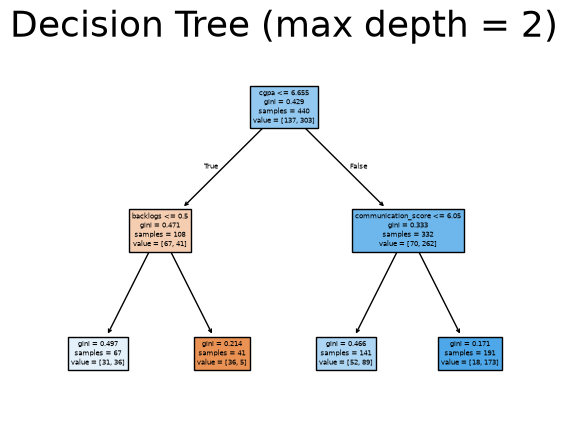

In [27]:
from sklearn.tree import plot_tree
plot_tree(model,
          feature_names=X.columns,
          filled=True)
plt.title('Decision Tree (max depth = 2)',fontsize=26)
plt.show()

### How to read one box

| Line in the box | Meaning | Root box |
|---|---|---|
| `cgpa <= 7.175` | The question. **True → go left**, False → go right | the best first question |
| `gini` | Impurity — 0 means pure | 0.491 |
| `samples` | Number of training students in this box | 440 |
| `value` | [not placed, placed] counts | [191, 249] |
| `class` | The majority class — the prediction if we stopped here | Placed |

- **Orange** boxes lean towards *Not placed*, **blue** boxes lean towards *Placed*. A darker colour means a purer box.
- The threshold **7.175** is the midpoint between two neighbouring CGPA values in the training data (7.17 and 7.18), the same midpoint method we used by hand. `export_text` below rounds it to 7.17.
- The tree picked `cgpa` as the root by itself — it reduces impurity the most, exactly like the highest information gain in our hand calculation.

## 🔮 8. Predict and check accuracy

> **Flow:** `predict` on the test data → `accuracy_score` on train and on test

In [28]:
y_pred = model.predict(X_test)
y_pred[:10]

array(['Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'Yes',
       'Yes'], dtype=object)

In [29]:
from sklearn.metrics import accuracy_score
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)
print('Train accuracy:',train_acc)
print('Test accuracy:',test_acc)

Train accuracy: 0.759090909090909
Test accuracy: 0.7545454545454545


## 🧮 9. Confusion matrix

> **Flow:** `confusion_matrix(y_test, y_pred)` → plot it with a seaborn heatmap

|  | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | TN — correctly said not placed | FP — said placed, but was not |
| **Actual 1** | FN — said not placed, but was placed | TP — correctly said placed |

In [30]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
cm

array([[11, 25],
       [ 2, 72]])

## 🌲 11. Let the tree grow fully — overfitting

> **Flow:** create a tree with **no** `max_depth` → fit → compare train and test accuracy

Without a limit, the tree keeps asking questions until every leaf is pure.

In [31]:
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [32]:
y_test1=full_tree.predict(X_train)
print('Depth:',full_tree.get_depth())
print('Leaves:',full_tree.get_n_leaves())

Depth: 11
Leaves: 82


In [33]:
print('Train accuracy:', round(accuracy_score(y_train, full_tree.predict(X_train)),3))
print('Test accuracy:', round(accuracy_score(y_test, full_tree.predict(X_test)),3))

Train accuracy: 1.0
Test accuracy: 0.782


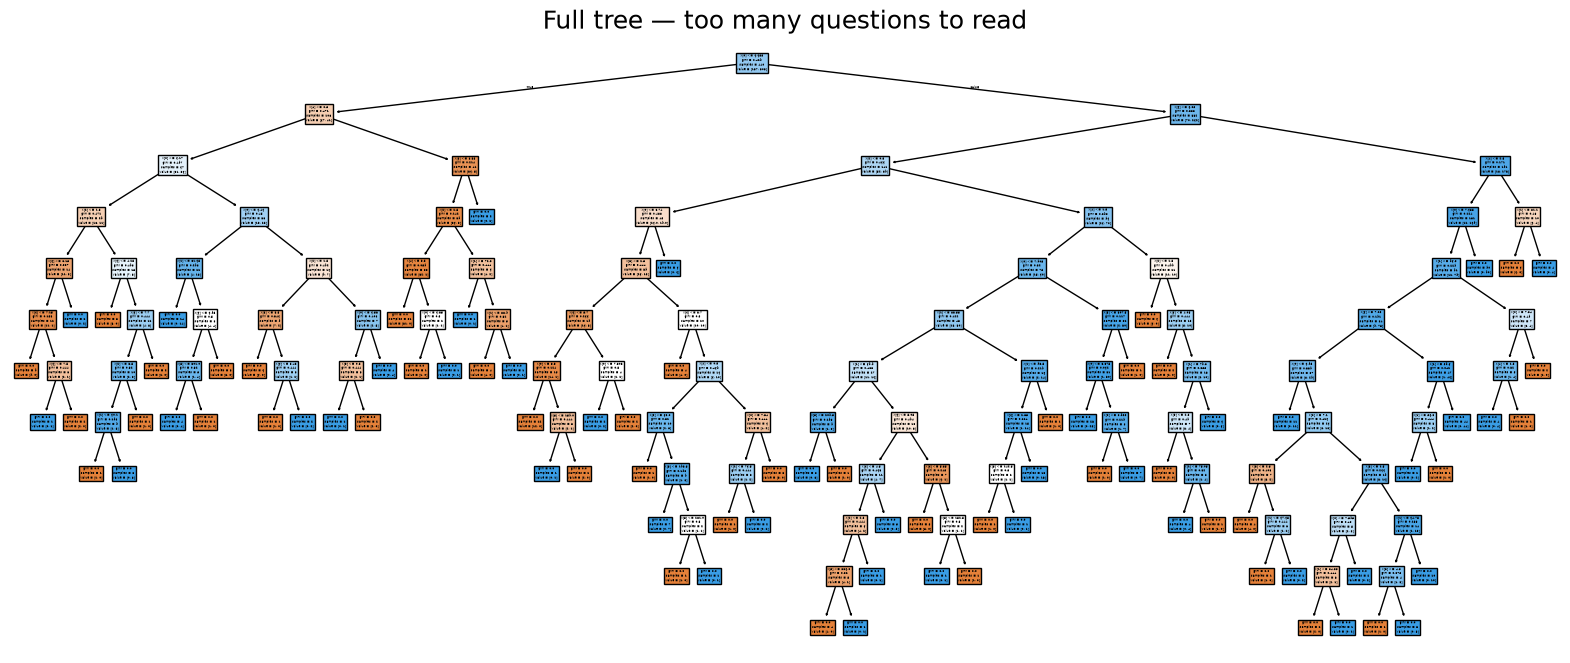

In [34]:
plt.figure(figsize=(20, 8))
plot_tree(full_tree, filled=True)
plt.title('Full tree — too many questions to read', fontsize=18)
plt.show()

### What happened?

- **Train accuracy = 1.00** — the tree is perfect on the students it has already seen.
- **Test accuracy ≈ 0.74** — on new students it is no better than our tiny 2-level tree (0.745). It is actually a little worse.
- With 13 levels and 82 leaves, many leaves hold only 1 or 2 students. Those questions describe **individual students (and their noise)**, not a general pattern.

This is **overfitting**: the model memorised the training data instead of learning from it.

## ⚖️ 13. Underfitting vs good fit vs overfitting

| | Underfitting | Good fit | Overfitting |
|---|---|---|---|
| **Model is** | too simple | just right | too complex |
| **Train accuracy** | low | high | very high (≈ 1.00) |
| **Test accuracy** | low | high | much lower than train |
| **Gap (train − test)** | small | small | **large** |
| **Our tree** | max_depth = 1 → 0.69 / 0.69 | max_depth = 3 → 0.78 / 0.78 | no limit → 1.00 / 0.74 |
| **Fix** | allow more depth | keep it | reduce `max_depth` |

- **Underfitting** — the model has not learned the pattern, so it does badly even on the training data. (Also called **high bias**.)
- **Overfitting** — the model memorised the training data, noise included, so it does badly on new testing data. (Also called **high variance**.)
- **Good fit** — test accuracy is as high as we can get **and** close to train accuracy.